In [31]:
import pandas as pd
from plotnine import (ggplot, aes, geom_bar, geom_line, geom_point, 
    coord_flip, theme_minimal, labs, theme, element_text
)

df = pd.read_csv("../data/CHART.CSV")

def clean_data(df):
    cleaned_df = df.copy()

    cleaned_df = cleaned_df.drop_duplicates()

    cleaned_df.columns = (
        cleaned_df.columns.str.strip()
        .str.lower()
        .str.replace(' ', '_')
    )

    text_columns = cleaned_df.select_dtypes(
        include=["object", "string"]
    ).columns
    for column in text_columns:
        cleaned_df[column] = cleaned_df[column].str.strip()

        cleaned_df[column] = cleaned_df[column].replace("", pd.NA)


    cleaned_df['current_balance'] = pd.to_numeric(
        cleaned_df['current_balance'],
        errors='raise')
    cleaned_df['next_check_number'] = pd.to_numeric(
        cleaned_df['next_check_number'], 
        errors='raise')

    return cleaned_df

cleaned_df = clean_data(df)
print(cleaned_df.head())

  account_id       account_description  account_type  inactive  tax_code  \
0   10000-00                Petty Cash             0     False       NaN   
1   10100-00              Cash on Hand             0     False       NaN   
2   10200-00  Regular Checking Account             0     False       NaN   
3   10300-00  Payroll Checking Account             0     False       NaN   
4   10400-00           Savings Account             0     False       NaN   

   next_check_number  current_balance  1099_settings  
0                NaN           327.55              0  
1                NaN          1850.45              0  
2            10211.0         23386.02              0  
3             1224.0          3711.09              0  
4                NaN          7500.00              0  


In [32]:
def transform_data(cleaned_df):

    transformed_df = cleaned_df.copy()
    account_parts = transformed_df['account_id'].str.split(
        '-', n=1, expand=True
    )

    transformed_df['account_number'] = account_parts[0]
    transformed_df['account_type'] = account_parts[1]

    return transformed_df

transformed_df = transform_data(cleaned_df)
print(transformed_df.head())
print(transformed_df.columns)


  account_id       account_description account_type  inactive  tax_code  \
0   10000-00                Petty Cash           00     False       NaN   
1   10100-00              Cash on Hand           00     False       NaN   
2   10200-00  Regular Checking Account           00     False       NaN   
3   10300-00  Payroll Checking Account           00     False       NaN   
4   10400-00           Savings Account           00     False       NaN   

   next_check_number  current_balance  1099_settings account_number  
0                NaN           327.55              0          10000  
1                NaN          1850.45              0          10100  
2            10211.0         23386.02              0          10200  
3             1224.0          3711.09              0          10300  
4                NaN          7500.00              0          10400  
Index(['account_id', 'account_description', 'account_type', 'inactive',
       'tax_code', 'next_check_number', 'current_balance'

In [33]:
df_general = pd.read_csv("../data/GENERAL.CSV")
df_general.head()


,Date,Reference,Date Clear in Bank Rec,Number of Distributions,G/L Account,Description,Amount,Job ID,Used for Reimbursable Expenses,Transaction Period,Transaction Number,Consolidated Transaction,Recur Number,Recur Frequency
0,1/31/26,FA012007,NaN,7,64000-00,Depreciation Expense - 01 2007,2818.56,NaN,False,15,1,False,0,0
1,1/31/26,FA012007,NaN,7,17000-00,Depreciation Expense - 01 2007,-420.80,NaN,False,15,1,False,0,0
2,1/31/26,FA012007,NaN,7,17100-00,Depreciation Expense - 01 2007,-442.31,NaN,False,15,1,False,0,0
3,1/31/26,FA012007,NaN,7,17200-00,Depreciation Expense - 01 2007,-1437.89,NaN,False,15,1,False,0,0
4,1/31/26,FA012007,NaN,7,17300-00,Depreciation Expense - 01 2007,-64.57,NaN,False,15,1,False,0,0


In [34]:
df_general.columns = (df_general.columns.str.strip()
.str.lower()
.str.replace(' ', '_'))

for column in df_general.columns:
    if df_general[column].dtype == ('object') or df_general[column].dtype == ('string'):
        df_general[column] = df_general[column].str.strip()
        df_general[column] = df_general[column].replace("", pd.NA)

df_general = df_general.rename(columns = {'g/l_account': 'account_id'})

account_parts = df_general['account_id'].str.split(
        '-', n=1, expand=True
    )
    
df_general['account_number'] = account_parts[0]
df_general['account_type'] = account_parts[1]

#print(df_general.head())
print(df_general.columns)

Index(['date', 'reference', 'date_clear_in_bank_rec',
       'number_of_distributions', 'account_id', 'description', 'amount',
       'job_id', 'used_for_reimbursable_expenses', 'transaction_period',
       'transaction_number', 'consolidated_transaction', 'recur_number',
       'recur_frequency', 'account_number', 'account_type'],
      dtype='str')


In [35]:
combined_df = pd.merge(
    df_general,
    transformed_df[['account_id', 'account_description', 'inactive', 'current_balance']],
    
    on = 'account_id',
    how = 'left'
)

combined_df['credit'] = combined_df['amount'].apply(lambda x: abs(x) if x < 0 else 0)
combined_df['debit'] = combined_df['amount'].apply(lambda x: x if x > 0 else 0)

print(combined_df.sort_values(by ='date')[:20])
print(combined_df.shape)

       date    reference  date_clear_in_bank_rec  number_of_distributions  \
0   1/31/26     FA012007                     NaN                        7   
1   1/31/26     FA012007                     NaN                        7   
2   1/31/26     FA012007                     NaN                        7   
3   1/31/26     FA012007                     NaN                        7   
4   1/31/26     FA012007                     NaN                        7   
5   1/31/26     FA012007                     NaN                        7   
6   1/31/26     FA012007                     NaN                        7   
8   2/12/26  PAYRL021207                     NaN                        2   
7   2/12/26  PAYRL021207                     NaN                        2   
15  2/28/26     FA022007                     NaN                        7   
9   2/28/26     FA022007                     NaN                        7   
10  2/28/26     FA022007                     NaN                        7   

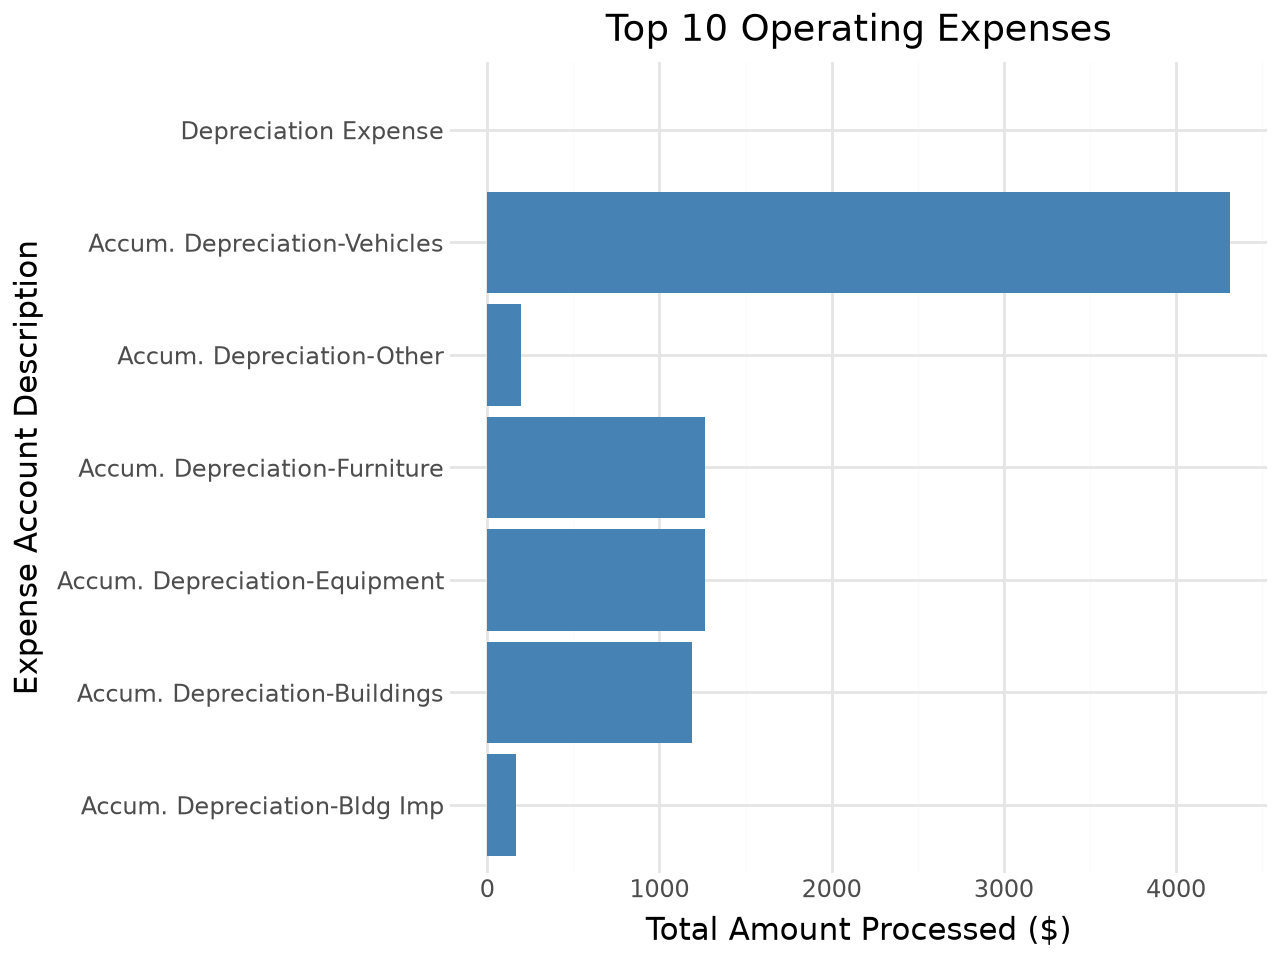

In [36]:


expense_summary = (combined_df[combined_df['account_description'].str.lower().str.contains('depreciation')].copy().groupby('account_description')
                   .sum()
                   .reset_index()
                   .sort_values(by='debit', ascending=False)
                   .head(10)
)
                                                                                                                    
chart_expenses = (ggplot(expense_summary,
                         aes (x = 'account_description',
                             y = 'debit' and 'credit'))
                             + geom_bar(stat = 'identity', fill = 'steelblue')
                             + coord_flip()
                             + theme_minimal()
                             + labs(
                                 title ='Top 10 Operating Expenses',
                                 x = 'Expense Account Description',
                                 y = 'Total Amount Processed ($)'
                             )
)

chart_expenses

In [37]:
print((combined_df[combined_df['account_description'].str.lower().str.contains('depreciation')].copy().groupby('account_description')
                   .sum()
                   .reset_index()
                   .sort_values(by='debit', ascending=False)
                   .head(10)))

             account_description                          date  \
6           Depreciation Expense         1/31/262/28/263/31/26   
2  Accum. Depreciation-Equipment  1/31/262/28/263/15/263/31/26   
3  Accum. Depreciation-Furniture  1/31/262/28/263/15/263/31/26   
1  Accum. Depreciation-Buildings  1/31/262/28/263/15/263/31/26   
0   Accum. Depreciation-Bldg Imp  1/31/262/28/263/15/263/31/26   
4      Accum. Depreciation-Other         1/31/262/28/263/31/26   
5   Accum. Depreciation-Vehicles         1/31/262/28/263/31/26   

                            reference  date_clear_in_bank_rec  \
6            FA012007FA022007FA032007                     0.0   
2  FA012007FA022007ADJ0303103FA032007                     0.0   
3  FA012007FA022007ADJ0303103FA032007                     0.0   
1  FA012007FA022007ADJ0303103FA032007                     0.0   
0  FA012007FA022007ADJ0303103FA032007                     0.0   
4            FA012007FA022007FA032007                     0.0   
5            FA0

In [38]:
print(expense_summary)

             account_description                          date  \
6           Depreciation Expense         1/31/262/28/263/31/26   
2  Accum. Depreciation-Equipment  1/31/262/28/263/15/263/31/26   
3  Accum. Depreciation-Furniture  1/31/262/28/263/15/263/31/26   
1  Accum. Depreciation-Buildings  1/31/262/28/263/15/263/31/26   
0   Accum. Depreciation-Bldg Imp  1/31/262/28/263/15/263/31/26   
4      Accum. Depreciation-Other         1/31/262/28/263/31/26   
5   Accum. Depreciation-Vehicles         1/31/262/28/263/31/26   

                            reference  date_clear_in_bank_rec  \
6            FA012007FA022007FA032007                     0.0   
2  FA012007FA022007ADJ0303103FA032007                     0.0   
3  FA012007FA022007ADJ0303103FA032007                     0.0   
1  FA012007FA022007ADJ0303103FA032007                     0.0   
0  FA012007FA022007ADJ0303103FA032007                     0.0   
4            FA012007FA022007FA032007                     0.0   
5            FA0